In [37]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import jax.numpy as np

import dLux as dl
import dLux.utils as dlu
import dLuxToliman as dlT
import src.OpticsSupport as OpticsSupport
import src.PlottingSupport as PlottingSupport
import src.STLMaker as STLMaker
import math
import scienceplots
from tqdm import tqdm

plt.style.use(["science", "bright", "no-latex"])

cividis = mpl.colormaps["cividis"]
viridis = mpl.colormaps["viridis"]
coolwarm = mpl.colormaps["coolwarm"]

cividis.set_bad("k", 1.0)
viridis.set_bad("k", 1.0)

mpl.colors.Normalize(vmin=-1, vmax=1)

In [38]:
plate_diameter = 0.00150
aperture_diameter = 0.00150
pix_over_125 = 200000

aperture_npix = int(round(pix_over_125*(aperture_diameter/0.125)))

conversion_factor = aperture_npix/aperture_diameter

# Defining grating period
period = 0.00015

X, Y = dlu.pixel_coords(aperture_npix, aperture_diameter)

In [39]:
# Defining offset of centre of circle (larger offset->more square)
offset = 600e-6

# Create an X-direction sinusoidal grating to fill the NaN regions.
# Use the same X grid and phase amplitude already defined in the notebook.

#sinusoidal_grating = np.pi/2 * np.sin(2 * np.pi * X / period) + np.pi
sawtooth_grating = (2*np.pi * X / period)%(2*np.pi) #+ np.pi/2

#circular_grating = np.pi/2 * np.sin(2*np.pi * np.sqrt(X**2+Y**2)/period) + np.pi
circular_grating = (2*np.pi * (np.sqrt(X**2+Y**2) / period))%(2*np.pi) #+ np.pi/2

# Creating radial sinusoid pattern with offset
# squary_grating_top = np.pi/2 * np.sin(2*np.pi * np.sqrt(X**2+(Y-offset)**2)/period) + np.pi
squary_grating_top = (2*np.pi * (np.sqrt(X**2+(Y-offset)**2) / period))%(2*np.pi) #+ np.pi/2

# Creating mask for top quarter
triangle_mask = np.triu(np.ones((int(aperture_npix/2),int(aperture_npix/2))))
print(triangle_mask.shape)
filler = np.zeros((int(aperture_npix/2),aperture_npix))
print(filler.shape)
triangle_mask = np.concatenate((triangle_mask,np.flip(triangle_mask,1)),axis=1)
squary_mask_top = np.concatenate((triangle_mask,filler))
squary_grating_phase_mask_top = np.where(squary_mask_top==0, 0 ,squary_grating_top)

# Duplicating for other quarters
squary_grating_phase_mask = squary_grating_phase_mask_top+np.rot90(squary_grating_phase_mask_top)+ np.rot90(squary_grating_phase_mask_top, k=2) + np.rot90(squary_grating_phase_mask_top, k=3)

# Removing double-ups along diagonals
squary_grating = squary_grating_phase_mask - np.multiply(squary_grating_phase_mask,np.eye(aperture_npix)/2) - np.multiply(squary_grating_phase_mask,np.rot90(np.eye(aperture_npix)/2,k=1))


square_grating_top = (2*np.pi * -Y/period)%(2*np.pi)
square_mask_top = np.concatenate((triangle_mask,filler))
square_grating_phase_mask_top = np.where(square_mask_top==0, 0 ,square_grating_top)
square_grating_phase_mask = square_grating_phase_mask_top+np.rot90(square_grating_phase_mask_top)+ np.rot90(square_grating_phase_mask_top, k=2) + np.rot90(square_grating_phase_mask_top, k=3)
square_grating_phase_mask = square_grating_phase_mask - np.multiply(square_grating_phase_mask,np.eye(aperture_npix)/2) - np.multiply(square_grating_phase_mask,np.rot90(np.eye(aperture_npix)/2,k=1))


(1200, 1200)
(1200, 2400)


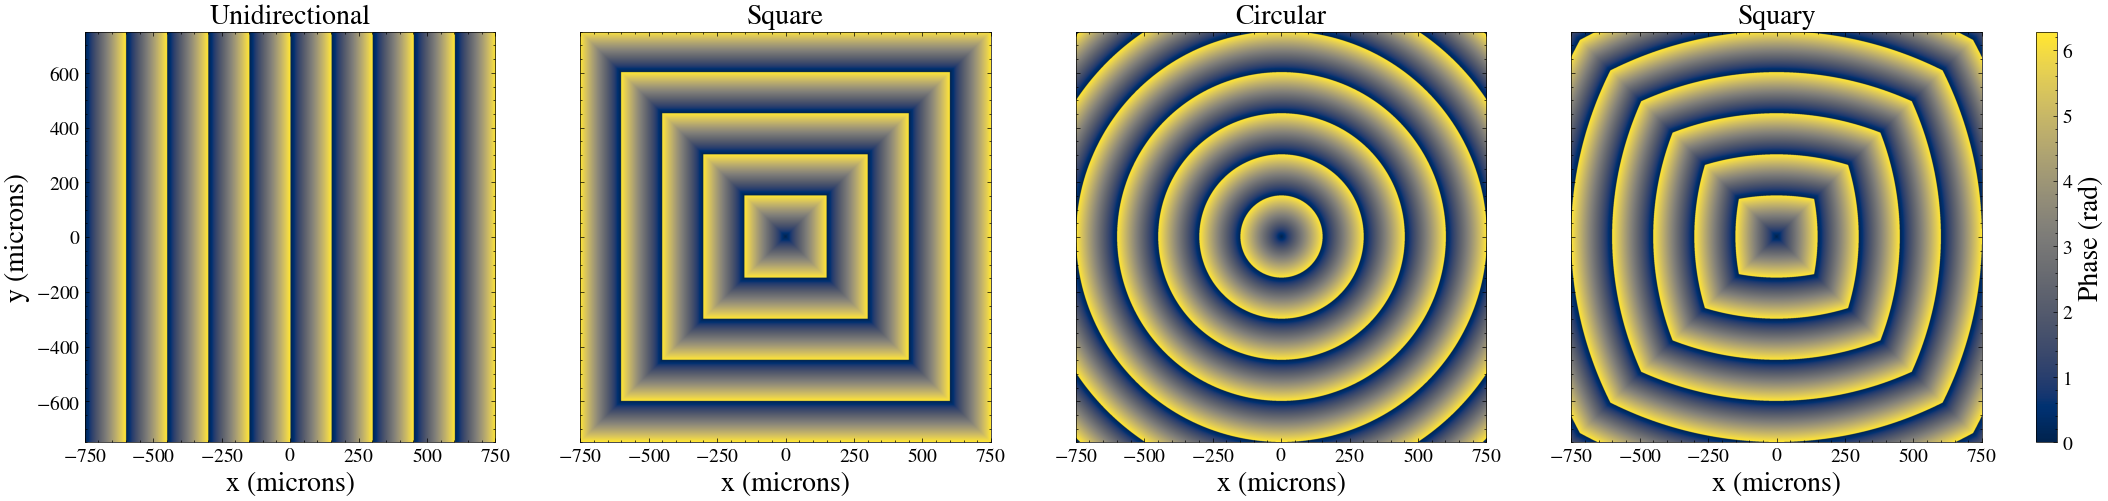

In [40]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

gratings = {
    "unidirectional": sawtooth_grating,
    "square": square_grating_phase_mask,
    "circular": circular_grating,
    "squary": squary_grating,
}

um_per_pix = 125e3/pix_over_125
# print(f"um per pixel: {um_per_pix}")
# half = square_grating_phase_mask.shape[0] * um_per_pix / 2
# fs = 20

# fig, ax = plt.subplots(figsize=(10, 10))
# im = ax.imshow(square_grating_phase_mask, cmap=cividis, extent=[-half, half, -half, half])
# ax.set_title("Square Grating External Mask", fontsize=30)
# ax.set_xlabel("x (microns)", fontsize=fs)
# ax.set_ylabel("y (microns)", fontsize=fs)
# ax.tick_params(axis="both", labelsize=fs)

# # Colorbar axes locked to the image axes' height
# cax = make_axes_locatable(ax).append_axes("right", size="5%", pad=0.15)
# cbar = fig.colorbar(im, cax=cax, )
# cbar.ax.tick_params(labelsize=fs)
# plt.show()

fs = 20
half = aperture_diameter * 1e6 / 2  # microns
fig, axes = plt.subplots(1, len(gratings), figsize=(5 * len(gratings) + 1, 5),
                         sharey=True, constrained_layout=True)
for ax, (name, inst) in zip(axes, gratings.items()):
    im = ax.imshow(inst, cmap=cividis, vmin=0, vmax=2 * np.pi,
                   extent=[-half, half, -half, half])
    ax.set_title(name.capitalize(), fontsize=fs)
    ax.set_xlabel("x (microns)", fontsize=fs)
    ax.tick_params(axis="both", labelsize=fs - 6)
axes[0].set_ylabel("y (microns)", fontsize=fs)

cbar = fig.colorbar(im, ax=axes, location="right", shrink=1, pad=0.02)
cbar.set_label("Phase (rad)", fontsize=fs)
cbar.ax.tick_params(labelsize=fs - 6)
plt.savefig("4_gratings_pupil.pdf", dpi=500)
plt.show()


In [20]:
plate_diameter = 0.125010
aperture_diameter = 0.125010
pix_over_125 = 5000

aperture_npix = int(round(pix_over_125*(aperture_diameter/0.125)))

conversion_factor = aperture_npix/aperture_diameter

# Defining grating period
period = 0.00015

X, Y = dlu.pixel_coords(aperture_npix, aperture_diameter)

In [21]:
# Defining offset of centre of circle (larger offset->more square)
offset = 50e-3

# Create an X-direction sinusoidal grating to fill the NaN regions.
# Use the same X grid and phase amplitude already defined in the notebook.

#sinusoidal_grating = np.pi/2 * np.sin(2 * np.pi * X / period) + np.pi
sawtooth_grating = (2*np.pi * X / period)%(2*np.pi) #+ np.pi/2

#circular_grating = np.pi/2 * np.sin(2*np.pi * np.sqrt(X**2+Y**2)/period) + np.pi
circular_grating = (2*np.pi * (np.sqrt(X**2+Y**2) / period))%(2*np.pi) #+ np.pi/2

# Creating radial sinusoid pattern with offset
# squary_grating_top = np.pi/2 * np.sin(2*np.pi * np.sqrt(X**2+(Y-offset)**2)/period) + np.pi
squary_grating_top = (2*np.pi * (np.sqrt(X**2+(Y-offset)**2) / period))%(2*np.pi) #+ np.pi/2

# Creating mask for top quarter
triangle_mask = np.triu(np.ones((int(aperture_npix/2),int(aperture_npix/2))))
print(triangle_mask.shape)
filler = np.zeros((int(aperture_npix/2),aperture_npix))
print(filler.shape)
triangle_mask = np.concatenate((triangle_mask,np.flip(triangle_mask,1)),axis=1)
squary_mask_top = np.concatenate((triangle_mask,filler))
squary_grating_phase_mask_top = np.where(squary_mask_top==0, 0 ,squary_grating_top)

# Duplicating for other quarters
squary_grating_phase_mask = squary_grating_phase_mask_top+np.rot90(squary_grating_phase_mask_top)+ np.rot90(squary_grating_phase_mask_top, k=2) + np.rot90(squary_grating_phase_mask_top, k=3)

# Removing double-ups along diagonals
squary_grating = squary_grating_phase_mask - np.multiply(squary_grating_phase_mask,np.eye(aperture_npix)/2) - np.multiply(squary_grating_phase_mask,np.rot90(np.eye(aperture_npix)/2,k=1))


square_grating_top = (2*np.pi * -Y/period)%(2*np.pi)
square_mask_top = np.concatenate((triangle_mask,filler))
square_grating_phase_mask_top = np.where(square_mask_top==0, 0 ,square_grating_top)
square_grating_phase_mask = square_grating_phase_mask_top+np.rot90(square_grating_phase_mask_top)+ np.rot90(square_grating_phase_mask_top, k=2) + np.rot90(square_grating_phase_mask_top, k=3)
square_grating_phase_mask = square_grating_phase_mask - np.multiply(square_grating_phase_mask,np.eye(aperture_npix)/2) - np.multiply(square_grating_phase_mask,np.rot90(np.eye(aperture_npix)/2,k=1))

(2500, 2500)
(2500, 5000)


In [41]:
gratings = {
    "unidirectional": sawtooth_grating,
    "square": square_grating_phase_mask,
    "circular": circular_grating,
    "squary": squary_grating,
}

um_per_pix = 2.74e-3

In [42]:
# Instrument parameters
wavelengths = np.linspace(530e-9, 640e-9, 30)  # Bandpass (m)
wf_npix = aperture_npix  # Downsampled wavefront sampling
psf_npix = 5000
plate_scale = 0.15625 #arcsec per micron
pixel_pitch = 2.74 #microns
psf_pixel_scale = plate_scale*pixel_pitch #arcsec per pixel

# Aperture transmission at the downsampled resolution
coords = dlu.pixel_coords(wf_npix, aperture_diameter)
aperture = dlu.circle(coords, aperture_diameter / 2)

def make_instrument(phase):
    # Downsample the complex field rather than the phase so the 2pi wraps
    # don't average to spurious intermediate phase values
    layers = [('aperture', dl.layers.Optic(aperture, phase=phase, normalise=True))]
    optics = dl.AngularOpticalSystem(
        wf_npixels=wf_npix,
        diameter=aperture_diameter,
        layers=layers,
        psf_npixels=psf_npix,
        psf_pixel_scale=psf_pixel_scale,
        oversample=1,
    )
    source = dl.PointSource(wavelengths=wavelengths, flux=10**7, position=(0, 0))
    return dl.Telescope(optics, source)


instruments = {name: make_instrument(phase) for name, phase in gratings.items()}

fs = 20
half = square_grating_phase_mask.shape[0] * um_per_pix / 2

In [ ]:

# Compute all PSFs and normalise each to unit total flux so they are comparable
psfs = {}
for name in gratings:
    print(f"Generating PSF for {name} grating...")
    psf = instruments[name].model()
    psfs[name] = psf / psf.sum()


Generating PSF for unidirectional grating...
Generating PSF for square grating...
Generating PSF for circular grating...
Generating PSF for squary grating...


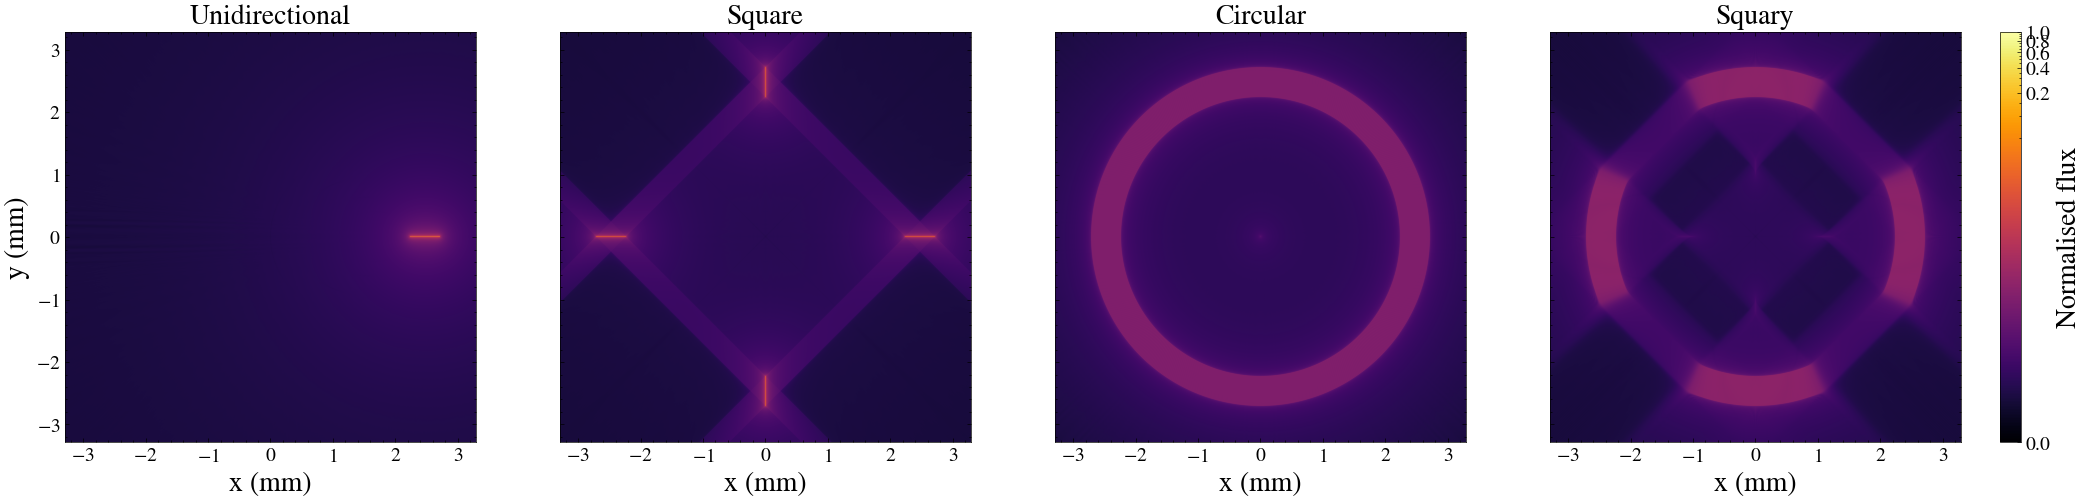

In [44]:
# Shared colour scale across all panels
vmax = max(float(p.max()) for p in psfs.values())

fig, axes = plt.subplots(1, len(gratings), figsize=(5 * len(gratings) + 1, 5),
                         sharey=True, constrained_layout=True)
for ax, (name, psf) in zip(axes, psfs.items()):
    im = ax.imshow(psf/vmax, cmap="inferno", norm=mpl.colors.PowerNorm(gamma=0.1, vmax=1),extent=[-half, half, -half, half])
    ax.set_title(name.capitalize(), fontsize=fs)
    ax.set_xlabel("x (mm)", fontsize=fs)
    ax.tick_params(axis="both", labelsize=fs - 6)
axes[0].set_ylabel("y (mm)", fontsize=fs)

cbar = fig.colorbar(im, ax=axes, location="right", shrink=1, pad=0.02)
cbar.set_label("Normalised flux", fontsize=fs)
cbar.ax.tick_params(labelsize=fs - 6)
plt.savefig("4_gratings_psf.pdf", dpi=500)
plt.show()
